In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import learning_curve

In [2]:
def plot_learning_curve(estimator, X, y, title, scoring):
    train_sizes, train_scores, val_scores = learning_curve(
        estimator,
        X,
        y,
        cv=5,
        scoring=scoring,
        train_sizes=np.linspace(0.1, 1.0, 10),
        n_jobs=-1,
        shuffle=True,
        random_state=42,
    )

    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)

    plt.figure(figsize=(8, 5))
    plt.title(title)
    plt.plot(train_sizes, train_mean, "o-", label="Train score")
    plt.plot(train_sizes, val_mean, "o-", label="Validation score")
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
    plt.xlabel("Number of training examples")
    plt.ylabel(scoring)
    plt.legend()
    plt.grid(True)
    plt.show()

In [3]:
X_cls, y_cls = make_classification(
    n_samples=1000,
    n_features=20,
    n_informative=10,
    n_redundant=5,
    random_state=42,
)

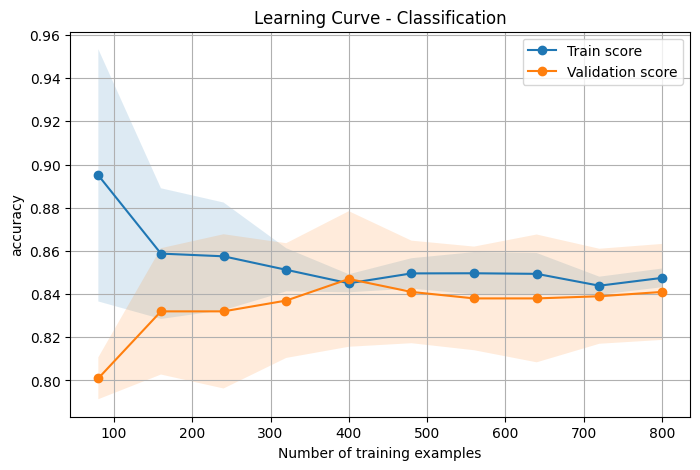

In [4]:
clf = LogisticRegression(max_iter=2000)
plot_learning_curve(
    clf,
    X_cls,
    y_cls,
    title="Learning Curve - Classification",
    scoring="accuracy",
)